# Notebook 12 — CICIDS2017 Model Comparison and Optimization

**AEGIS AI-Powered Intrusion Detection System · Sprint 4**

**Purpose:** Compare the existing Random Forest binary IDS baseline from Notebook 11 with Logistic Regression and HistGradientBoosting using the **same five live-target features and validation split** created by Notebook 10. Then conduct an initial, controlled tuning experiment and examine attack-category misses.

**Rules:**
- Keep Notebook 11 and `aegis_cicids2017_binary_rf_v1.joblib` unchanged.
- Train alternative models **only** with Notebook 10's training partition. Use the validation partition for model comparison and exploratory tuning. **Do not load the held-out test split in this notebook.**
- Initial alternatives use a stratified **training subset** for speed; consequently, this is an exploratory comparison with the full-data Random Forest. Report the unequal training budgets.
- Reusing validation to pick models or tune thresholds makes the resulting validation metrics selection-biased. A new, independent evaluation is required before promoting a new model.
- These are historical CIC-IDS2017 results; **live feature equivalence remains unverified**. None of the models in this notebook create AEGIS alerts.

Run the cells in order. Model training may take time depending on available memory/CPU.

## 1. Imports, paths, and experiment configuration

In [1]:
from pathlib import Path
import json
import platform
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / 'ml' / 'data' / 'processed').is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open the notebook inside the AEGIS repository.')

SPLIT_DIR = PROJECT_ROOT / 'ml' / 'data' / 'processed' / 'model_ready'
MODEL_DIR = PROJECT_ROOT / 'ml' / 'models' / 'cicids2017_baseline'
OUTPUT_DIR = PROJECT_ROOT / 'ml' / 'evaluation' / 'cicids2017_comparison'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FEATURES = [
    'Flow Duration',
    'Total Fwd Packets',
    'Total Backward Packets',
    'Flow Bytes/s',
    'Flow Packets/s',
]
TARGET = 'BinaryLabel'
RANDOM_STATE = 42
TRAIN_SAMPLE_SIZE = 250_000
COMMON_THRESHOLD = 0.50

print('Repository:', PROJECT_ROOT)
print('Model-ready data:', SPLIT_DIR)
print('Evaluation output:', OUTPUT_DIR)
print('Python:', platform.python_version())
print('scikit-learn:', sklearn.__version__)

Repository: c:\Users\SOYUZ\Documents\CPSC-491\AI-Intrusion-Detection-System
Model-ready data: c:\Users\SOYUZ\Documents\CPSC-491\AI-Intrusion-Detection-System\ml\data\processed\model_ready
Evaluation output: c:\Users\SOYUZ\Documents\CPSC-491\AI-Intrusion-Detection-System\ml\evaluation\cicids2017_comparison
Python: 3.11.0
scikit-learn: 1.9.0


## 2. Load and validate only the training and validation partitions

Notebook 10 exported `BinaryLabel` (0=BENIGN, 1=ATTACK), original `Label` for category analysis, and five numeric features. Metadata is **not** used as model input.

In [2]:
train_path = SPLIT_DIR / 'CICIDS2017_Binary_train.csv'
validation_path = SPLIT_DIR / 'CICIDS2017_Binary_validation.csv'
for path in (train_path, validation_path):
    if not path.is_file():
        raise FileNotFoundError(f'Missing Notebook 10 output: {path}')

columns = FEATURES + [TARGET, 'Label']
train_df = pd.read_csv(train_path, usecols=columns)
val_df = pd.read_csv(validation_path, usecols=columns)

for name, frame in [('train', train_df), ('validation', val_df)]:
    if frame.empty:
        raise ValueError(f'{name} split is empty')
    if frame[columns].isna().any().any():
        raise ValueError(f'{name} split has missing feature/label values')
    if not np.isfinite(frame[FEATURES].to_numpy(dtype=np.float64)).all():
        raise ValueError(f'{name} split has nonfinite features')
    if set(frame[TARGET].unique()) != {0, 1}:
        raise ValueError(f'{name} must contain exactly classes 0 and 1')
    print(name, 'rows:', len(frame), 'binary class counts:',
          frame[TARGET].value_counts().sort_index().to_dict())

print('Five ordered features:', FEATURES)
display(val_df.head())

train rows: 1791100 binary class counts: {0: 1490344, 1: 300756}
validation rows: 376404 binary class counts: {0: 318106, 1: 58298}
Five ordered features: ['Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s']


,Flow Duration,Total Fwd Packets,Total Backward Packets,Flow Bytes/s,Flow Packets/s,BinaryLabel,Label
0,4,2,0,3.000000e+06,500000.000000,0,BENIGN
1,609,7,4,1.474548e+06,18062.397373,0,BENIGN
2,927,9,6,6.709817e+06,16181.229773,0,BENIGN
3,77033,13,11,6.698428e+04,311.554788,0,BENIGN
4,4,2,0,3.000000e+06,500000.000000,0,BENIGN


## 3. Prepare a stratified exploratory training sample

The original Random Forest remains trained on **all** Notebook 11 training rows. Logistic Regression and HistGradientBoosting are first trained on at most 250,000 rows from the same training partition. The full validation partition is used for evaluation.

In [3]:
if len(train_df) > TRAIN_SAMPLE_SIZE:
    sampled_train, _ = train_test_split(
        train_df,
        train_size=TRAIN_SAMPLE_SIZE,
        stratify=train_df[TARGET],
        random_state=RANDOM_STATE,
    )
else:
    sampled_train = train_df.copy()

X_train = sampled_train[FEATURES].astype('float32')
y_train = sampled_train[TARGET].astype('int8')
X_val = val_df[FEATURES].astype('float32')
y_val = val_df[TARGET].astype('int8')
print('Alternative model training rows:', len(X_train))
print('Full validation rows:', len(X_val))
print('Sample class distribution:')
display(y_train.value_counts().sort_index())

Alternative model training rows: 250000
Full validation rows: 376404
Sample class distribution:


BinaryLabel
0    208021
1     41979
Name: count, dtype: int64

## 4. Shared binary classification evaluation function

All three models are measured on the **same validation rows** at an initial common threshold of 0.50. Attack (`1`) is the positive class. A non-finite probability or a model lacking class `1` causes an explicit error.

In [4]:
def evaluate_probabilities(model_name, y_true, attack_prob, threshold=0.50, training_rows=None):
    y_true = np.asarray(y_true, dtype=int)
    attack_prob = np.asarray(attack_prob, dtype=float)
    if len(y_true) != len(attack_prob) or not np.isfinite(attack_prob).all():
        raise ValueError('Invalid or mismatched prediction probabilities')

    predicted = (attack_prob >= threshold).astype('int8')
    tn, fp, fn, tp = confusion_matrix(
        y_true, predicted, labels=[0, 1]
    ).ravel()
    return {
        'Model': model_name,
        'Training Rows': training_rows,
        'Threshold': float(threshold),
        'Accuracy': float(accuracy_score(y_true, predicted)),
        'Balanced Accuracy': float(balanced_accuracy_score(y_true, predicted)),
        'Precision': float(precision_score(y_true, predicted, zero_division=0)),
        'Recall': float(recall_score(y_true, predicted, zero_division=0)),
        'F1': float(f1_score(y_true, predicted, zero_division=0)),
        'ROC-AUC': float(roc_auc_score(y_true, attack_prob)),
        'Average Precision': float(average_precision_score(y_true, attack_prob)),
        'False Positive Rate': float(fp / (fp + tn)),
        'False Negative Rate': float(fn / (fn + tp)),
        'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp),
    }


def attack_probabilities(model, X):
    classes = list(model.classes_)
    if 1 not in classes:
        raise ValueError(f'ATTACK class (1) missing: {classes}')
    return np.asarray(model.predict_proba(X)[:, classes.index(1)])

## 5. Load the existing Random Forest baseline (do not retrain)

Only load **your own trusted** `.joblib` artifact. Confirm feature ordering from Notebook 11 metadata. The comparison at threshold 0.50 uses **validation** metrics, not the previously reported test metrics.

In [5]:
rf_path = MODEL_DIR / 'aegis_cicids2017_binary_rf_v1.joblib'
metadata_path = MODEL_DIR / 'aegis_cicids2017_binary_rf_v1.metadata.json'
if not rf_path.is_file() or not metadata_path.is_file():
    raise FileNotFoundError('Run Notebook 11 or restore its local model and metadata first.')

with metadata_path.open(encoding='utf-8') as f:
    rf_metadata = json.load(f)
if rf_metadata.get('feature_names_ordered') != FEATURES:
    raise ValueError('Saved Random Forest feature order does not match Notebook 12')

rf_model = joblib.load(rf_path)  # Trusted, locally trained artifact only.
rf_prob = attack_probabilities(rf_model, X_val)
rf_results = evaluate_probabilities(
    'Random Forest (existing)', y_val, rf_prob,
    threshold=COMMON_THRESHOLD,
    training_rows=rf_metadata.get('training_records'),
)
display(pd.DataFrame([rf_results]).round(5))

,Model,Training Rows,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,False Positive Rate,False Negative Rate,TN,FP,FN,TP
0,Random Forest (existing),1791100,0.5,0.99226,0.98889,0.9666,0.98401,0.97523,0.99874,0.99384,0.00623,0.01599,316124,1982,932,57366


## 6. Train Logistic Regression

Only the training partition fits `StandardScaler`; validation values are transformed by the same fitted scaler. `class_weight="balanced"` helps account for unequal class frequencies.

In [6]:
lr_model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        class_weight='balanced',
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])
lr_model.fit(X_train, y_train)
lr_prob = attack_probabilities(lr_model, X_val)
lr_results = evaluate_probabilities(
    'Logistic Regression', y_val, lr_prob,
    threshold=COMMON_THRESHOLD, training_rows=len(X_train),
)
print('Logistic Regression complete')
display(pd.DataFrame([lr_results]).round(5))

Logistic Regression complete


,Model,Training Rows,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,False Positive Rate,False Negative Rate,TN,FP,FN,TP
0,Logistic Regression,250000,0.5,0.81109,0.6641,0.40209,0.45115,0.42521,0.72999,0.40558,0.12294,0.54885,278997,39109,31997,26301


## 7. Train HistGradientBoosting

HistGradientBoosting provides a second nonlinear classifier. Initial parameters are conservative to make the experiment practical. No previously deployed artifacts are replaced.

In [7]:
hgb_model = HistGradientBoostingClassifier(
    max_iter=100,
    learning_rate=0.10,
    max_leaf_nodes=31,
    l2_regularization=1.0,
    early_stopping=True,
    random_state=RANDOM_STATE,
)
hgb_model.fit(X_train, y_train)
hgb_prob = attack_probabilities(hgb_model, X_val)
hgb_results = evaluate_probabilities(
    'HistGradientBoosting', y_val, hgb_prob,
    threshold=COMMON_THRESHOLD, training_rows=len(X_train),
)
print('HistGradientBoosting complete')
display(pd.DataFrame([hgb_results]).round(5))

HistGradientBoosting complete


,Model,Training Rows,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,False Positive Rate,False Negative Rate,TN,FP,FN,TP
0,HistGradientBoosting,250000,0.5,0.99032,0.97898,0.97462,0.96255,0.96855,0.99773,0.98991,0.00459,0.03745,316645,1461,2183,56115


## 8. Side-by-side validation comparison

At this point the existing Random Forest had a **larger training budget**. Treat the rankings as candidate screening, not evidence that an algorithm is inherently superior. F1 is used here to sort the initial comparison; attack recall and false-positive rate must also be reviewed.

,Model,Training Rows,Threshold,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,Average Precision,False Positive Rate,False Negative Rate,FP,FN
0,Random Forest (existing),1791100,0.5,0.99226,0.98889,0.96660,0.98401,0.97523,0.99874,0.99384,0.00623,0.01599,1982,932
1,HistGradientBoosting,250000,0.5,0.99032,0.97898,0.97462,0.96255,0.96855,0.99773,0.98991,0.00459,0.03745,1461,2183
2,Logistic Regression,250000,0.5,0.81109,0.66410,0.40209,0.45115,0.42521,0.72999,0.40558,0.12294,0.54885,39109,31997


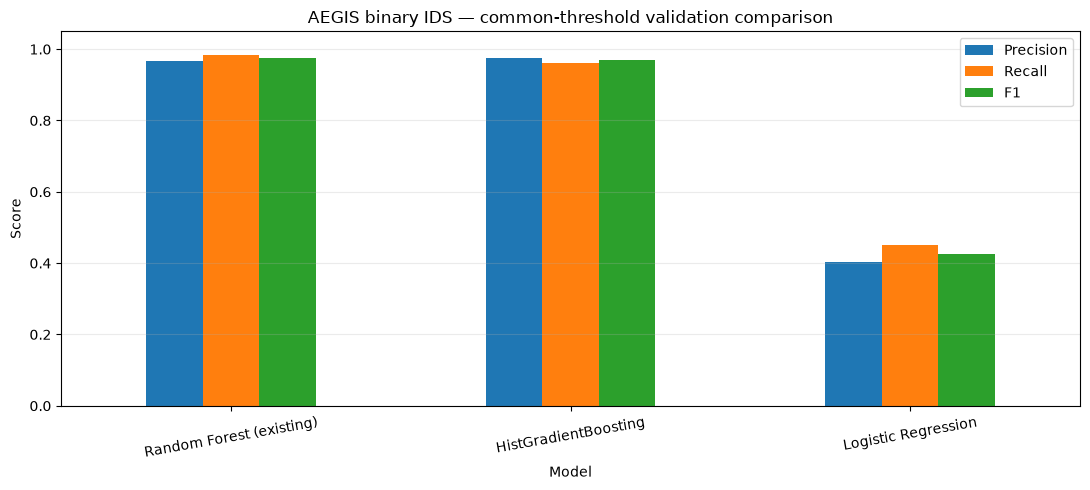

In [8]:
comparison = pd.DataFrame([rf_results, lr_results, hgb_results])
comparison = comparison.sort_values('F1', ascending=False).reset_index(drop=True)
view_columns = [
    'Model', 'Training Rows', 'Threshold', 'Accuracy', 'Balanced Accuracy',
    'Precision', 'Recall', 'F1', 'ROC-AUC', 'Average Precision',
    'False Positive Rate', 'False Negative Rate', 'FP', 'FN',
]
display(comparison[view_columns].round(5))

ax = comparison.set_index('Model')[['Precision', 'Recall', 'F1']].plot(
    kind='bar', figsize=(11, 5), rot=10
)
ax.set_title('AEGIS binary IDS — common-threshold validation comparison')
ax.set_ylabel('Score')
ax.set_ylim(0, 1.05)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'validation_model_comparison.png', dpi=170)
plt.show()

## 9. False positives, false negatives, and confusion matrices

,Model,TN,FP,FN,TP,False Positive Rate,False Negative Rate
0,Random Forest (existing),316124,1982,932,57366,0.00623,0.01599
1,HistGradientBoosting,316645,1461,2183,56115,0.00459,0.03745
2,Logistic Regression,278997,39109,31997,26301,0.12294,0.54885


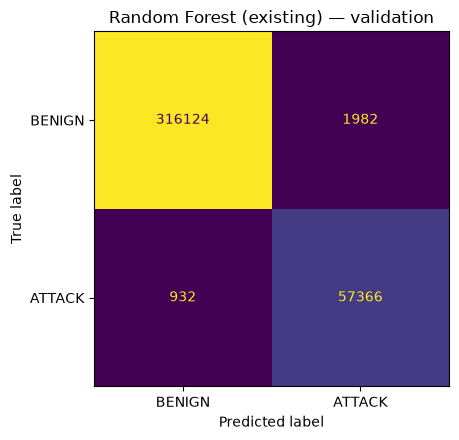

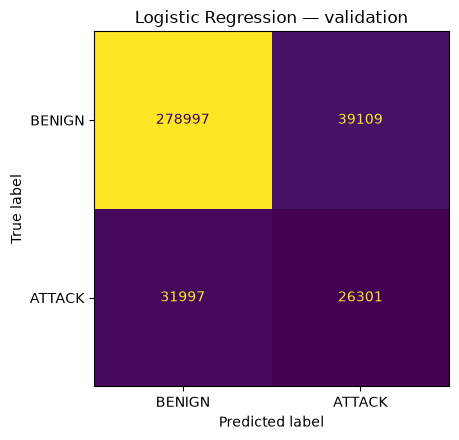

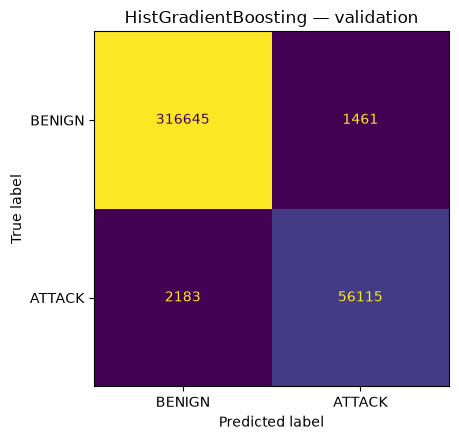

In [9]:
display(comparison[['Model', 'TN', 'FP', 'FN', 'TP',
                    'False Positive Rate', 'False Negative Rate']].round(5))

probability_by_model = {
    'Random Forest (existing)': rf_prob,
    'Logistic Regression': lr_prob,
    'HistGradientBoosting': hgb_prob,
}
for name, probabilities in probability_by_model.items():
    prediction = (probabilities >= COMMON_THRESHOLD).astype(int)
    matrix = confusion_matrix(y_val, prediction, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ConfusionMatrixDisplay(matrix, display_labels=['BENIGN', 'ATTACK']).plot(
        ax=ax, colorbar=False
    )
    ax.set_title(name + ' — validation')
    plt.tight_layout()
    safe_name = name.lower().replace(' ', '_').replace('(', '').replace(')', '')
    plt.savefig(OUTPUT_DIR / f'{safe_name}_validation_confusion_matrix.png', dpi=160)
    plt.show()

## 10. Attack-category detection analysis

For the validation partition, examine **attack-class recall by original CIC-IDS2017 category**. The model is binary, so these are not multiclass predictions. Categories with very few rows produce unstable percentages.

In [10]:
def category_detection_report(model_name, probabilities, threshold=0.50):
    predictions = probabilities >= threshold
    attack_rows = val_df[TARGET].to_numpy() == 1
    frame = pd.DataFrame({
        'Label': val_df.loc[attack_rows, 'Label'].to_numpy(),
        'Detected': predictions[attack_rows].astype(int),
    })
    report = frame.groupby('Label', as_index=False).agg(
        Total=('Detected', 'size'),
        Detected=('Detected', 'sum'),
    )
    report['Missed'] = report['Total'] - report['Detected']
    report['Detection Rate (%)'] = (100 * report['Detected'] / report['Total']).round(2)
    report.insert(0, 'Model', model_name)
    return report.sort_values('Detection Rate (%)')

category_reports = pd.concat([
    category_detection_report(name, prob)
    for name, prob in probability_by_model.items()
], ignore_index=True)
display(category_reports.sort_values(['Label', 'Model']))
print('Small categories should not be interpreted as reliable standalone estimates.')

,Model,Label,Total,Detected,Missed,Detection Rate (%)
33,HistGradientBoosting,Bot,335,54,281,16.12
14,Logistic Regression,Bot,335,0,335,0.00
5,Random Forest (existing),Bot,335,193,142,57.61
41,HistGradientBoosting,DDoS,19019,18925,94,99.51
22,Logistic Regression,DDoS,19019,3300,15719,17.35
12,Random Forest (existing),DDoS,19019,18986,33,99.83
35,HistGradientBoosting,DoS GoldenEye,1518,1342,176,88.41
23,Logistic Regression,DoS GoldenEye,1518,400,1118,26.35
8,Random Forest (existing),DoS GoldenEye,1518,1487,31,97.96
40,HistGradientBoosting,DoS Hulk,26162,25391,771,97.05


Small categories should not be interpreted as reliable standalone estimates.


## 11. Exploratory threshold optimization on the validation set

Explore common threshold values **for candidate selection only**. This is a continuation of Notebook 11’s validation-threshold exercise, now applied to all three classifiers. Because we choose on validation, the best validation F1 becomes selection-biased. Do not claim it as independent final performance. If false positives carry a high operational cost, use additional constraints rather than blindly maximizing F1.

,Model,Threshold,Precision,Recall,F1,False Positive Rate,False Negative Rate
0,HistGradientBoosting,0.45,0.97285,0.96623,0.96953,0.00494,0.03377
1,Logistic Regression,0.70,0.53116,0.44063,0.48168,0.07128,0.55937
2,Random Forest (existing),0.50,0.96660,0.98401,0.97523,0.00623,0.01599


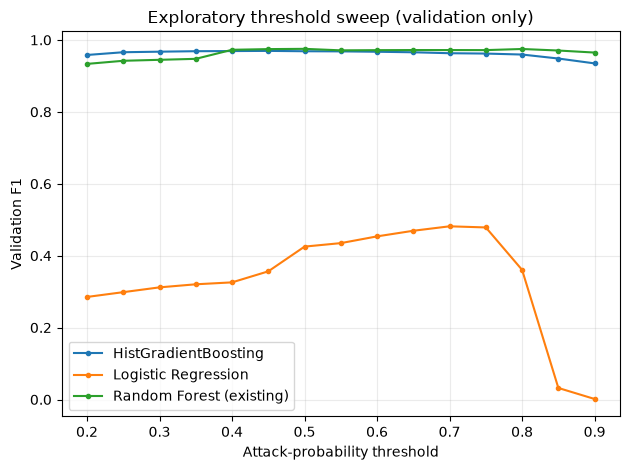

In [11]:
threshold_grid = np.round(np.arange(0.20, 0.91, 0.05), 2)
threshold_rows = []
for name, probabilities in probability_by_model.items():
    for threshold in threshold_grid:
        result = evaluate_probabilities(
            name, y_val, probabilities, threshold=float(threshold),
            training_rows=(rf_metadata.get('training_records')
                           if name == 'Random Forest (existing)' else len(X_train)),
        )
        threshold_rows.append(result)
threshold_comparison = pd.DataFrame(threshold_rows)

best_thresholds = (
    threshold_comparison.sort_values(['Model', 'F1', 'Recall'],
                                     ascending=[True, False, False])
    .groupby('Model', as_index=False).first()
)
display(best_thresholds[['Model', 'Threshold', 'Precision', 'Recall', 'F1',
                         'False Positive Rate', 'False Negative Rate']].round(5))

for name, frame in threshold_comparison.groupby('Model'):
    plt.plot(frame['Threshold'], frame['F1'], marker='.', label=name)
plt.xlabel('Attack-probability threshold')
plt.ylabel('Validation F1')
plt.title('Exploratory threshold sweep (validation only)')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'validation_threshold_sweep.png', dpi=170)
plt.show()

## 12. Exploratory HistGradientBoosting hyperparameter comparison

Train two additional HistGradientBoosting configurations on the **same sampled training data**, then examine validation performance. This is **not** a nested search or an independent final estimate. Keep the existing Random Forest untouched. A later step should retrain promising candidates on the full training partition and evaluate with an independent, session-aware dataset.

In [12]:
hgb_candidates = [
    {'max_iter': 150, 'learning_rate': 0.07, 'max_leaf_nodes': 31, 'l2_regularization': 1.0},
    {'max_iter': 150, 'learning_rate': 0.07, 'max_leaf_nodes': 15, 'l2_regularization': 2.0},
]
tuning_results = []
tuned_hgb_models = {}
for index, params in enumerate(hgb_candidates, start=1):
    candidate = HistGradientBoostingClassifier(
        **params,
        early_stopping=True,
        random_state=RANDOM_STATE,
    )
    candidate.fit(X_train, y_train)
    prob = attack_probabilities(candidate, X_val)
    name = f'HistGB tuned candidate {index}'
    tuned_hgb_models[name] = candidate
    metrics = evaluate_probabilities(
        name, y_val, prob, threshold=COMMON_THRESHOLD,
        training_rows=len(X_train),
    )
    metrics.update({'Settings': json.dumps(params)})
    tuning_results.append(metrics)

tuning_table = pd.DataFrame(tuning_results).sort_values('F1', ascending=False)
display(tuning_table[['Model', 'Settings', 'Precision', 'Recall', 'F1',
                      'False Positive Rate', 'False Negative Rate']].round(5))

,Model,Settings,Precision,Recall,F1,False Positive Rate,False Negative Rate
0,HistGB tuned candidate 1,"{""max_iter"": 150, ""learning_rate"": 0.07, ""max_...",0.97694,0.96091,0.96886,0.00416,0.03909
1,HistGB tuned candidate 2,"{""max_iter"": 150, ""learning_rate"": 0.07, ""max_...",0.97498,0.93713,0.95568,0.00441,0.06287


## 13. Save Sprint 4 comparison evidence

Save **metrics and plots only**. No model is automatically promoted or written over the deployed Random Forest. Report reproducibility settings and validation-selection limitations alongside the results.

In [13]:
comparison.to_csv(OUTPUT_DIR / 'model_validation_comparison.csv', index=False)
category_reports.to_csv(OUTPUT_DIR / 'validation_attack_category_detection.csv', index=False)
threshold_comparison.to_csv(OUTPUT_DIR / 'validation_threshold_comparison.csv', index=False)
tuning_table.to_csv(OUTPUT_DIR / 'histgb_exploratory_tuning.csv', index=False)

manifest = {
    'dataset': 'CICIDS2017',
    'splits': 'Notebook 10 deterministic five-feature-signature split',
    'features_ordered': FEATURES,
    'target': TARGET,
    'positive_class': 1,
    'common_threshold': COMMON_THRESHOLD,
    'initial_alternative_training_rows': int(len(X_train)),
    'validation_rows': int(len(X_val)),
    'random_state': RANDOM_STATE,
    'reference_random_forest': rf_metadata.get('model_id'),
    'reference_random_forest_training_rows': rf_metadata.get('training_records'),
    'python': platform.python_version(),
    'scikit_learn': sklearn.__version__,
    'notes': [
        'No held-out test split was loaded in Notebook 12.',
        'Threshold and hyperparameter exploration on validation are selection-biased.',
        'Original Random Forest was fitted on the full training partition.',
        'Alternatives initially used an exploratory stratified training sample.',
        'Live AEGIS feature equivalence is not verified.',
        'Do not promote or overwrite the deployed model based on these results alone.',
    ],
}
with (OUTPUT_DIR / 'experiment_manifest.json').open('w', encoding='utf-8') as file:
    json.dump(manifest, file, indent=2)

print('Saved experiment evidence to:', OUTPUT_DIR)
for path in sorted(OUTPUT_DIR.iterdir()):
    print(' -', path.name)

Saved experiment evidence to: c:\Users\SOYUZ\Documents\CPSC-491\AI-Intrusion-Detection-System\ml\evaluation\cicids2017_comparison
 - experiment_manifest.json
 - histgb_exploratory_tuning.csv
 - histgradientboosting_validation_confusion_matrix.png
 - logistic_regression_validation_confusion_matrix.png
 - model_validation_comparison.csv
 - random_forest_existing_validation_confusion_matrix.png
 - validation_attack_category_detection.csv
 - validation_model_comparison.png
 - validation_threshold_comparison.csv
 - validation_threshold_sweep.png


## 14. Sprint 4 Findings and Next Actions

### 14.1 Model Comparison Results

Three machine-learning classifiers were successfully trained or loaded and evaluated using the CIC-IDS2017 validation dataset containing **376,404 network-flow records**.

All models used the same five input features and were initially compared using a classification threshold of **0.50**.

| Metric | Random Forest | HistGradientBoosting | Logistic Regression |
|---|---:|---:|---:|
| Training Records | 1,791,100 | 250,000 | 250,000 |
| Accuracy | **99.23%** | 99.03% | 81.11% |
| Precision | 96.66% | **97.46%** | 40.21% |
| Attack Recall | **98.40%** | 96.26% | 45.12% |
| F1-Score | **97.52%** | 96.86% | 42.52% |
| False-Positive Rate | 0.62% | **0.46%** | 12.29% |
| False-Negative Rate | **1.60%** | 3.75% | 54.89% |
| False Positives | 1,982 | **1,461** | 39,109 |
| False Negatives | **932** | 2,183 | 31,997 |

### 14.2 Summary of Findings

| Question | Finding |
|---|---|
| Best validation F1 at a common 0.50 threshold | **Random Forest — 97.52%** |
| Highest attack recall at a common 0.50 threshold | **Random Forest — 98.40%** |
| Lowest false-positive rate | **HistGradientBoosting — 0.46%** |
| Weakest attack categories | **Web Attack - XSS, Web Attack - Brute Force, and Bot** were consistently challenging. Detection was particularly poor for the two web attack categories. |
| Most promising alternative for full-data training | **HistGradientBoosting**, because it achieved strong overall validation performance and fewer false positives despite using fewer training records. |
| Preferred existing AEGIS model | **Random Forest**, based on higher validation F1-score, higher attack recall, and fewer missed attacks. |

### 14.3 Threshold Optimization Findings

Classification thresholds were evaluated using the validation dataset to investigate precision-recall tradeoffs.

| Model | Selected Threshold | Precision | Recall | F1-Score |
|---|---:|---:|---:|---:|
| Random Forest | 0.50 | 96.66% | 98.40% | **97.52%** |
| HistGradientBoosting | 0.45 | 97.29% | 96.62% | 96.95% |
| Logistic Regression | 0.70 | 53.12% | 44.06% | 48.17% |

Reducing the HistGradientBoosting threshold from 0.50 to 0.45 slightly improved attack recall and F1-score but increased its false-positive rate.

Random Forest retained the highest validation F1-score among the evaluated models and thresholds.

These thresholds were selected using validation data and should not be considered independently validated operating points.

### 14.4 HistGradientBoosting Hyperparameter Optimization

Two additional HistGradientBoosting configurations were evaluated.

| Model | Precision | Recall | F1-Score | False-Positive Rate |
|---|---:|---:|---:|---:|
| Original HistGradientBoosting | 97.46% | 96.26% | 96.86% | 0.459% |
| Tuned Candidate 1 | **97.69%** | 96.09% | **96.89%** | **0.416%** |
| Tuned Candidate 2 | 97.50% | 93.71% | 95.57% | 0.441% |

Tuned Candidate 1 achieved a small improvement in F1-score and reduced false positives, but its attack recall declined slightly.

Tuned Candidate 2 produced lower attack recall and a higher false-negative rate, making it a less promising candidate.

Neither configuration demonstrated a sufficient overall improvement to justify replacing the existing Random Forest baseline.

### 14.5 Attack-Category Error Analysis

Category-level analysis revealed that model performance varies substantially depending on attack type.

The Random Forest achieved strong validation detection rates for several categories:

- **PortScan:** 99.86%
- **DDoS:** 99.83%
- **DoS Hulk:** 98.72%
- **FTP-Patator:** 97.50%

However, the model struggled with several attack categories:

| Attack Category | Total Samples | Detected by Random Forest | Missed | Detection Rate |
|---|---:|---:|---:|---:|
| Web Attack - XSS | 114 | 4 | 110 | **3.51%** |
| Web Attack - Brute Force | 203 | 15 | 188 | **7.39%** |
| Bot | 335 | 193 | 142 | **57.61%** |

These results indicate that the current five-feature representation may not contain sufficient information to distinguish certain application-layer attack patterns from benign network activity.

Additional feature engineering and category-specific evaluation should be investigated.

Categories containing only one or a few validation samples, such as Heartbleed and Infiltration, cannot provide reliable standalone estimates of detection performance.

### 14.6 Model Selection Decision

**The existing Random Forest remains the provisional preferred model for AEGIS.**

The decision is supported by:

- Highest validation F1-score of **97.52%**.
- Highest overall attack recall of **98.40%**.
- Lowest false-negative count among the three initial classifiers (**932 missed attacks**).
- Strong detection performance on several high-volume attack categories.
- Existing integration with the AEGIS experimental inference pipeline.

HistGradientBoosting remains the strongest alternative for future optimization, particularly because it achieved fewer false positives with a smaller training sample.

Logistic Regression is not recommended for replacement of the current baseline under its evaluated configuration because of its substantially lower attack recall and F1-score.

**The existing model artifact will remain unchanged:**

`ml/models/cicids2017_baseline/aegis_cicids2017_binary_rf_v1.joblib`

No alternative model will replace the current baseline without additional evaluation and regression testing.

### 14.7 Evaluation Evidence

Notebook 12 successfully generated the following files in:

`ml/evaluation/cicids2017_comparison/`

- `experiment_manifest.json`
- `model_validation_comparison.csv`
- `validation_model_comparison.png`
- `validation_threshold_comparison.csv`
- `validation_threshold_sweep.png`
- `histgb_exploratory_tuning.csv`
- `validation_attack_category_detection.csv`
- `random_forest_existing_validation_confusion_matrix.png`
- `histgradientboosting_validation_confusion_matrix.png`
- `logistic_regression_validation_confusion_matrix.png`

These artifacts document the exploratory model comparison, threshold optimization, hyperparameter experiments, and attack-category evaluation.

### 14.8 What This Notebook Does Not Prove

The results do **not** establish:

- That AEGIS achieves 99% intrusion-detection accuracy on live network traffic.
- That the smaller-sample alternatives have been compared under equal training conditions with the full-data Random Forest.
- That the selected thresholds and hyperparameters will generalize to new traffic sessions.
- That the five live AEGIS flow features are equivalent to the CIC-IDS2017 feature definitions and units.
- That the existing evaluation split eliminates all near-duplicate, session-level, or temporal data leakage.
- That weak attack categories will be detected reliably in deployment.

The validation data was reused for model comparison and optimization, so the reported validation metrics are subject to model-selection bias.

### 14.9 Recommended Next Iteration

1. **Full-data model comparison:** Retrain HistGradientBoosting using the complete training partition and compare against Random Forest under more comparable training conditions.
2. **Improved validation methodology:** If tuning becomes extensive, create a group-aware development holdout inside the training partition and reserve the existing validation data for final candidate comparison.
3. **Feature engineering:** Investigate additional features for weak attack categories, particularly Web Attack - XSS, Web Attack - Brute Force, and Bot.
4. **Independent evaluation:** Evaluate the selected model on new capture sessions or appropriately separated datasets to assess generalization.
5. **Live feature equivalence:** Verify that AEGIS produces the same feature definitions, units, and ordering used during CIC-IDS2017 training.
6. **Model versioning:** Save future candidate models under distinct filenames with accompanying metadata.
7. **Backend regression testing:** Validate inference compatibility before integrating any replacement model.

### 14.10 Sprint 4 Conclusion

Sprint 4 successfully established an exploratory comparison of three machine-learning classifiers, evaluated classification thresholds, tested alternative HistGradientBoosting configurations, and analyzed attack-category detection weaknesses.

The existing Random Forest demonstrated the strongest overall validation performance and remains the provisional preferred model for AEGIS.

HistGradientBoosting showed promising results and should be considered for additional full-data experimentation.

**Sprint 4's initial model comparison and exploratory optimization objectives are complete.** Further independent evaluation, feature engineering, and live feature-equivalence testing remain necessary before making production-readiness claims.

---

**Notebook 12 ends here.**